# Multimodal Meme Sentiment Classification (Memotion 7k)

**Task.** Predict the overall sentiment of an internet meme (negative / neutral / positive) from its **image** and its **overlaid text**.

**Approaches compared**

| # | Model | Fusion type |
|---|---|---|
| 1 | Image-only (ResNet-50 features → MLP) | unimodal baseline |
| 2 | Text-only (BERT features → MLP) | unimodal baseline |
| 3 | Early fusion (normalise + concatenate → MLP) | feature-level |
| 4 | Late fusion (average / weighted average of 1 and 2) | decision-level |
| 5 | Cross-attention fusion (text tokens ↔ image regions) | intermediate / attention |
| ref | CLIP ViT-B/32 linear probe | reference only, not a main model |

**How to run.** In Colab: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Expected run time is about 20–30 minutes; most of it is image feature extraction, which is cached in `features/` so re-runs are fast. All tables and figures are written to `results/` and zipped at the end.

> ⚠️ **Content warning:** memes in this dataset can contain offensive, crude or stereotyping content. The failure-case gallery (Section 11) shows real examples.

In [1]:
# Colab already ships torch, torchvision, transformers, scikit-learn, pandas and matplotlib.
!pip -q install kagglehub

## 1. Setup and configuration
Every setting used in the experiments lives in `CFG`, and is saved to `results/config.json`.

In [2]:
import os, re, io, json, time, glob, hashlib, random, zipfile, textwrap, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, roc_auc_score, confusion_matrix, cohen_kappa_score)
from tqdm.auto import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None          # some memes are very large; the dataset is trusted

CFG = dict(
    seeds=[42, 43, 44],                 # every trained model is run with 3 seeds -> mean ± std
    split=(0.70, 0.15, 0.15),           # stratified train / val / test
    img_size=224,                       # whole meme squashed to 224x224 (no centre-crop, so no text is cut off)
    image_model="ResNet-50, ImageNet IMAGENET1K_V2 weights, frozen",
    text_model="bert-base-uncased, frozen, mean-pooled last layer",
    max_len=None,                       # chosen from the token-length distribution in Section 5
    hidden=256, dropout=0.3,            # MLP head
    lr_mlp=1e-3, lr_xattn=3e-4, weight_decay=1e-2,
    batch=64, epochs=40, patience=6,    # early stopping on validation macro-F1
    xattn_dim=256, xattn_heads=4,
    loss="cross-entropy with inverse-frequency class weights",
    run_cross_attention=True, run_clip_reference=True,
    n_bootstrap=1000,
)
CLASSES = ["negative", "neutral", "positive"]
SENT_MAP = {"very_negative": "negative", "negative": "negative", "neutral": "neutral",
            "positive": "positive", "very_positive": "positive"}

OUT = Path("results"); FIG = OUT / "figures"; TAB = OUT / "tables"; FEAT = Path("features")
for d in (FIG, TAB, FEAT):
    d.mkdir(parents=True, exist_ok=True)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 2 if DEV.type == "cuda" else 0
TIMES = {}
print("Device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "(no GPU - this will be slow)")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)

def save_table(df_, name, index=True):
    df_.to_csv(TAB / f"{name}.csv", index=index)

Device: cuda Tesla T4


In [3]:
# Plot style: one fixed colour per model, used in every figure.
PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
           magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
MODEL_ORDER = ["Majority class", "Image-only", "Text-only", "Early fusion", "Late fusion (mean)",
               "Late fusion (weighted)", "Cross-attention", "CLIP linear probe (ref.)"]
MODEL_COLORS = {"Image-only": PAL["blue"], "Text-only": PAL["orange"], "Early fusion": PAL["aqua"],
                "Late fusion (mean)": PAL["yellow"], "Late fusion (weighted)": PAL["magenta"],
                "Cross-attention": PAL["green"], "CLIP linear probe (ref.)": PAL["violet"], "Majority class": MUTED}
SEQ = LinearSegmentedColormap.from_list("seq_blue", [SURF, "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 10, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 10, "lines.linewidth": 2,
})
def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show(); plt.close(fig)

## 2. Load the dataset
Memotion 7k (Sharma et al., 2020, SemEval-2020 Task 8), downloaded from Kaggle with `kagglehub` (no login needed).

In [4]:
import kagglehub
DATA_ROOT = Path(kagglehub.dataset_download("williamscott701/memotion-dataset-7k"))

  0%|          | 0.00/695M [00:00<?, ?B/s]

  1%|          | 5.00M/695M [00:00<00:14, 50.5MB/s]

  3%|▎         | 24.0M/695M [00:00<00:05, 135MB/s] 

  7%|▋         | 49.0M/695M [00:00<00:03, 190MB/s]

 10%|█         | 71.0M/695M [00:00<00:03, 198MB/s]

 14%|█▍        | 96.0M/695M [00:00<00:02, 219MB/s]

... (27 outputs left out)

 96%|█████████▋| 670M/695M [00:06<00:00, 72.1MB/s]

 98%|█████████▊| 684M/695M [00:06<00:00, 83.0MB/s]

100%|██████████| 695M/695M [00:06<00:00, 116MB/s] 

Extracting files...


In [5]:
labels_csv = sorted(DATA_ROOT.rglob("labels.csv"))[0]
IMG_DIR = labels_csv.parent / "images"
raw = pd.read_csv(labels_csv)
raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]
print(raw.shape, "| images folder:", IMG_DIR)
display(raw.head(3))

(6992, 8) | images folder: /root/.cache/kagglehub/datasets/williamscott701/memotion-dataset-7k/versions/1/memotion_dataset_7k/images


,image_name,text_ocr,text_corrected,humour,sarcasm,offensive,motivational,overall_sentiment
0,image_1.jpg,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,hilarious,general,not_offensive,not_motivational,very_positive
1,image_2.jpeg,The best of #10 YearChallenge! Completed in le...,The best of #10 YearChallenge! Completed in le...,not_funny,general,not_offensive,motivational,very_positive
2,image_3.JPG,Sam Thorne @Strippin ( Follow Follow Saw every...,Sam Thorne @Strippin ( Follow Follow Saw every...,very_funny,not_sarcastic,not_offensive,not_motivational,positive


## 3. Label mapping and text preprocessing
* The 5-point `overall_sentiment` is merged into 3 classes (very_negative + negative → negative, very_positive + positive → positive).
* **Text source:** the hand-corrected text is the main input; if it is empty we fall back to the raw OCR text; if both are empty we use a `[NO TEXT]` placeholder.
* **Cleaning:** meme-generator watermarks and URLs (e.g. `memegenerator.net`) are removed and whitespace is normalised. Lower-casing is done by the uncased BERT tokenizer.

In [6]:
URL_RE = re.compile(r"(?:https?://\S+|www\.\S+|\b[\w-]+\.(?:com|net|org|co|in|ly)\b\S*)", re.I)

def clean_text(t):
    if not isinstance(t, str):
        return ""
    return re.sub(r"\s+", " ", URL_RE.sub(" ", t)).strip()

df = raw.copy()
df["label_name"] = df["overall_sentiment"].map(SENT_MAP)
assert df["label_name"].notna().all(), "unexpected sentiment value"
df["label"] = df["label_name"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)

corr, ocr = df["text_corrected"].map(clean_text), df["text_ocr"].map(clean_text)
df["had_url"] = (df["text_corrected"].fillna("").str.contains(URL_RE) |
                 df["text_ocr"].fillna("").str.contains(URL_RE))
df["text"] = np.where(corr.str.len() > 0, corr, np.where(ocr.str.len() > 0, ocr, "[NO TEXT]"))
df["text_source"] = np.where(corr.str.len() > 0, "corrected", np.where(ocr.str.len() > 0, "ocr_fallback", "none"))
df["n_words"] = np.where(df["text_source"] == "none", 0, df["text"].str.split().str.len())
df["path"] = df["image_name"].map(lambda n: str(IMG_DIR / n))

print(df["text_source"].value_counts().to_string())
print("Memes with a URL / watermark removed:", int(df["had_url"].sum()))

text_source
corrected       6987
none               4
ocr_fallback       1
Memes with a URL / watermark removed: 2196


## 4. Data quality assessment
Every image is decoded once to find unreadable files, record sizes and formats, and hash the bytes to find exact duplicates (which would leak between splits).

In [7]:
def inspect_image(path):
    rec = dict(ok=False, width=np.nan, height=np.nan, format=None, n_frames=1, file_kb=np.nan, md5=None, error=None)
    try:
        data = Path(path).read_bytes()
        rec["file_kb"], rec["md5"] = len(data) / 1024, hashlib.md5(data).hexdigest()
        im = Image.open(io.BytesIO(data))
        rec["format"], rec["n_frames"] = im.format, getattr(im, "n_frames", 1)
        im.seek(0)
        rec["width"], rec["height"] = im.convert("RGB").size
        rec["ok"] = True
    except Exception as e:
        rec["error"] = type(e).__name__
    return rec

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    recs = list(tqdm(ex.map(inspect_image, df["path"]), total=len(df), desc="Checking images"))
df = pd.concat([df.reset_index(drop=True), pd.DataFrame(recs)], axis=1)
TIMES["image_check_s"] = time.time() - t0
print(f"Checked {len(df)} images in {TIMES['image_check_s']:.0f}s")

Checking images:   0%|          | 0/6992 [00:00<?, ?it/s]

Checked 6992 images in 26s


In [8]:
n_total = len(df)
bad = df[~df["ok"]]
dup_mask = df["ok"] & df.duplicated("md5", keep="first")
dup_groups = df[df["ok"] & df["md5"].duplicated(keep=False)].groupby("md5")["label"].nunique()
w = df.loc[df.ok, "n_words"]

quality = pd.DataFrame([
    ("Memes in labels.csv", n_total),
    ("Unreadable or missing image files (removed)", len(bad)),
    ("Exact duplicate images (removed, keep first)", int(dup_mask.sum())),
    ("Duplicate groups with conflicting labels", int((dup_groups > 1).sum())),
    ("Raw OCR text missing", int(raw["text_ocr"].isna().sum())),
    ("Corrected text missing", int(raw["text_corrected"].isna().sum())),
    ("Both texts missing -> [NO TEXT] placeholder", int((df["text_source"] == "none").sum())),
    ("OCR fallback used", int((df["text_source"] == "ocr_fallback").sum())),
    ("Texts with URL / watermark removed", int(df["had_url"].sum())),
    ("Animated GIFs (first frame used)", int((df["n_frames"] > 1).sum())),
    ("Image formats", ", ".join(f"{k}: {v}" for k, v in df["format"].value_counts().items())),
    ("Median image size (w x h)", f"{df.width.median():.0f} x {df.height.median():.0f}"),
    ("Smallest / largest image width", f"{df.width.min():.0f} / {df.width.max():.0f}"),
    ("Words per meme: median / 95th pct / max", f"{w.median():.0f} / {w.quantile(.95):.0f} / {w.max():.0f}"),
], columns=["check", "value"])
if len(bad):
    print("Unreadable files by error type:", bad["error"].value_counts().to_dict())

df = df[df["ok"] & ~dup_mask].reset_index(drop=True)
quality.loc[len(quality)] = ("Memes kept for modelling", len(df))
for c in CLASSES:
    n = int((df.label_name == c).sum())
    quality.loc[len(quality)] = (f"Class '{c}'", f"{n} ({n / len(df):.1%})")
save_table(quality, "data_quality", index=False)
display(quality)

Unreadable files by error type: {'OSError': 1}


,check,value
0,Memes in labels.csv,6992
1,Unreadable or missing image files (removed),1
2,"Exact duplicate images (removed, keep first)",25
3,Duplicate groups with conflicting labels,11
4,Raw OCR text missing,161
5,Corrected text missing,5
6,Both texts missing -> [NO TEXT] placeholder,4
7,OCR fallback used,1
8,Texts with URL / watermark removed,2196
9,Animated GIFs (first frame used),1


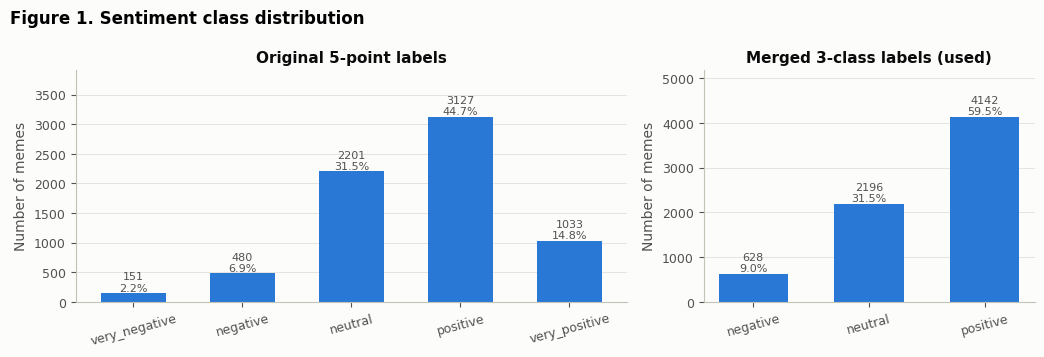

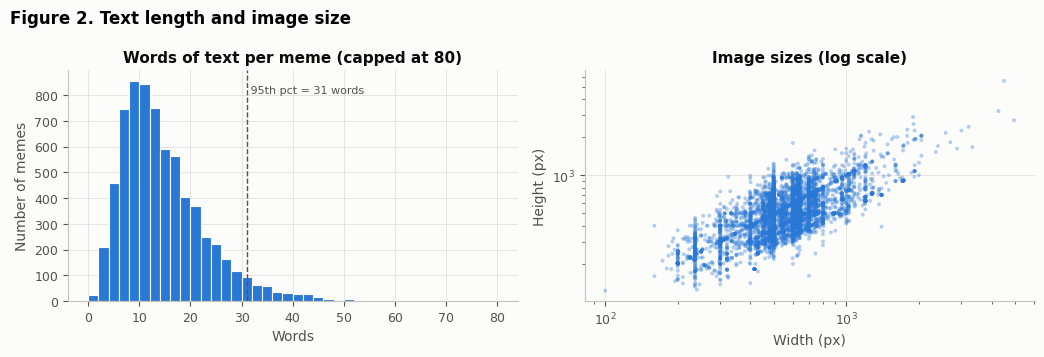

In [9]:
order5 = ["very_negative", "negative", "neutral", "positive", "very_positive"]
c5 = raw["overall_sentiment"].value_counts().reindex(order5).fillna(0)
c3 = df["label_name"].value_counts().reindex(CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [5, 3]})
for ax, counts, title in [(axes[0], c5, "Original 5-point labels"), (axes[1], c3, "Merged 3-class labels (used)")]:
    bars = ax.bar(counts.index, counts.values, color=PAL["blue"], width=0.6)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{int(v)}\n{v / counts.sum():.1%}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_title(title); ax.set_ylabel("Number of memes"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, counts.max() * 1.25); ax.tick_params(axis="x", rotation=15)
fig.suptitle("Figure 1. Sentiment class distribution", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); savefig(fig, "fig01_class_distribution")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax = axes[0]
ax.hist(df["n_words"].clip(upper=80), bins=40, color=PAL["blue"], edgecolor=SURF, linewidth=0.8)
p95 = df["n_words"].quantile(.95)
ax.axvline(p95, color=INK2, ls="--", lw=1); ax.text(p95, ax.get_ylim()[1] * .9, f" 95th pct = {p95:.0f} words", color=INK2, fontsize=8)
ax.set_title("Words of text per meme (capped at 80)"); ax.set_xlabel("Words"); ax.set_ylabel("Number of memes")
ax = axes[1]
ax.scatter(df["width"], df["height"], s=8, alpha=.35, color=PAL["blue"], edgecolors="none")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Image sizes (log scale)"); ax.set_xlabel("Width (px)"); ax.set_ylabel("Height (px)")
fig.suptitle("Figure 2. Text length and image size", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); savefig(fig, "fig02_text_and_image_stats")

## 5. Train / validation / test split
Stratified 70/15/15 split with a fixed seed. The test set is used **only** for the final numbers; model selection (early stopping, late-fusion weight, CLIP's C) uses validation only.

In [10]:
idx_all = np.arange(len(df))
tr_idx, tmp_idx = train_test_split(idx_all, test_size=CFG["split"][1] + CFG["split"][2], stratify=df["label"], random_state=42)
va_idx, te_idx = train_test_split(tmp_idx, test_size=CFG["split"][2] / (CFG["split"][1] + CFG["split"][2]),
                                  stratify=df["label"].iloc[tmp_idx], random_state=42)
df["split"] = "train"; df.loc[va_idx, "split"] = "val"; df.loc[te_idx, "split"] = "test"
split_tab = pd.crosstab(df["split"], df["label_name"], margins=True).reindex(["train", "val", "test", "All"])[CLASSES + ["All"]]
save_table(split_tab, "split_sizes"); display(split_tab)
y_tr, y_va, y_te = (df.loc[df.split == s, "label"].to_numpy() for s in ["train", "val", "test"])

label_name,negative,neutral,positive,All
split,,,,
train,440,1537,2899,4876
val,94,329,622,1045
test,94,330,621,1045
All,628,2196,4142,6966


## 6. Feature extraction (frozen pretrained encoders)
Both backbones stay **frozen**: with ~4.9k training memes, fine-tuning 25M (ResNet-50) + 110M (BERT) parameters would overfit quickly and would not fit the free Colab budget. Features are extracted once and cached.

* **Image:** ResNet-50 (He et al., 2016). We keep the last convolutional map (7×7×2048): its average is the 2048-d *pooled* vector, and its 49 cells are the *region tokens* used by cross-attention.
* **Text:** BERT-base-uncased (Devlin et al., 2019). The mean of the last layer over real tokens gives the 768-d *sentence* vector; the full token sequence is kept for cross-attention.

In [11]:
from transformers import AutoTokenizer, AutoModel
TOK = AutoTokenizer.from_pretrained("bert-base-uncased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [12]:
tok_lens = np.array([len(ids) for ids in TOK(df["text"].tolist(), add_special_tokens=True)["input_ids"]])
p95_tok = int(np.percentile(tok_lens, 95))
CFG["max_len"] = 64 if p95_tok <= 64 else 128
trunc_rate = float((tok_lens > CFG["max_len"]).mean())
print(f"BERT tokens per meme: median {np.median(tok_lens):.0f}, 95th pct {p95_tok}, max {tok_lens.max()}")
print(f"max_len = {CFG['max_len']}  ->  {trunc_rate:.1%} of memes are truncated")

BERT tokens per meme: median 18, 95th pct 45, max 251
max_len = 64  ->  0.9% of memes are truncated


In [13]:
from torchvision.models import resnet50, ResNet50_Weights
cnn = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


  0%|          | 0.00/97.8M [00:00<?, ?B/s]

  7%|▋         | 7.00M/97.8M [00:00<00:01, 73.4MB/s]

 30%|███       | 29.4M/97.8M [00:00<00:00, 168MB/s] 

 53%|█████▎    | 52.0M/97.8M [00:00<00:00, 199MB/s]

 73%|███████▎  | 71.0M/97.8M [00:00<00:00, 187MB/s]

 91%|█████████ | 89.0M/97.8M [00:00<00:00, 180MB/s]

100%|██████████| 97.8M/97.8M [00:00<00:00, 178MB/s]

In [14]:
from torchvision import transforms as T
IMG_BACKBONE = nn.Sequential(*list(cnn.children())[:-2]).eval().to(DEV)   # drop avgpool + fc
for p in IMG_BACKBONE.parameters():
    p.requires_grad = False
img_tf = T.Compose([T.Resize((CFG["img_size"], CFG["img_size"])), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class ImageDS(torch.utils.data.Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        im = Image.open(self.paths[i]); im.seek(0)
        return img_tf(im.convert("RGB"))

img_cache = FEAT / "image_features.pt"
if img_cache.exists() and torch.load(img_cache)["names"] == df["image_name"].tolist():
    c = torch.load(img_cache); IMG_POOL, IMG_TOK = c["pool"], c["tok"]
    TIMES["image_features_s"] = c["secs"]; print("Loaded cached image features")
else:
    loader = torch.utils.data.DataLoader(ImageDS(df["path"].tolist()), batch_size=64, num_workers=NUM_WORKERS,
                                         pin_memory=DEV.type == "cuda")
    pools, toks = [], []
    t0 = time.time()
    with torch.no_grad(), torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=DEV.type == "cuda"):
        for x in tqdm(loader, desc="ResNet-50"):
            fm = IMG_BACKBONE(x.to(DEV, non_blocking=True))                 # (B, 2048, 7, 7)
            pools.append(fm.float().mean((2, 3)).cpu())
            toks.append(fm.flatten(2).transpose(1, 2).half().cpu())        # (B, 49, 2048)
    IMG_POOL, IMG_TOK = torch.cat(pools), torch.cat(toks)
    TIMES["image_features_s"] = time.time() - t0
    torch.save(dict(names=df["image_name"].tolist(), pool=IMG_POOL, tok=IMG_TOK, secs=TIMES["image_features_s"]), img_cache)
print("Image features:", tuple(IMG_POOL.shape), tuple(IMG_TOK.shape), f"| {TIMES['image_features_s']:.0f}s")
del IMG_BACKBONE, cnn

ResNet-50:   0%|          | 0/109 [00:00<?, ?it/s]

Image features: (6966, 2048) (6966, 49, 2048) | 56s


In [15]:
BERT = AutoModel.from_pretrained("bert-base-uncased")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [16]:
BERT = BERT.eval().to(DEV)
texts, L = df["text"].tolist(), CFG["max_len"]
means, clss, toks, masks = [], [], [], []
t0 = time.time()
with torch.no_grad(), torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=DEV.type == "cuda"):
    for i in tqdm(range(0, len(texts), 128), desc="BERT"):
        enc = TOK(texts[i:i + 128], padding="max_length", truncation=True, max_length=L, return_tensors="pt").to(DEV)
        h = BERT(**enc).last_hidden_state.float()                            # (B, L, 768)
        m = enc["attention_mask"].unsqueeze(-1).float()
        means.append(((h * m).sum(1) / m.sum(1)).cpu()); clss.append(h[:, 0].cpu())
        toks.append(h.half().cpu()); masks.append(enc["attention_mask"].bool().cpu())
TXT_MEAN, TXT_CLS, TXT_TOK, TXT_MASK = map(torch.cat, (means, clss, toks, masks))
TIMES["text_features_s"] = time.time() - t0
print("Text features:", tuple(TXT_MEAN.shape), tuple(TXT_TOK.shape), f"| {TIMES['text_features_s']:.0f}s")
del BERT
if DEV.type == "cuda":
    torch.cuda.empty_cache()

BERT:   0%|          | 0/55 [00:00<?, ?it/s]

Text features: (6966, 768) (6966, 64, 768) | 6s


### 6b. CLIP reference features (optional)
CLIP (Radford et al., 2021) is used **only as a reference point**, as the brief requires: a logistic-regression probe on frozen CLIP image + text embeddings.

In [17]:
CLIP_IMG = CLIP_TXT = None
if CFG["run_clip_reference"]:
    try:
        from transformers import CLIPModel, CLIPProcessor
        clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval().to(DEV)
        proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
        as_t = lambda o: o if torch.is_tensor(o) else (o.pooler_output if getattr(o, "pooler_output", None) is not None else o[0])
        ci, ct = [], []
        t0 = time.time()
        with torch.no_grad():
            for i in tqdm(range(0, len(df), 64), desc="CLIP"):
                rows = df.iloc[i:i + 64]
                ims = []
                for p in rows["path"]:
                    im = Image.open(p); im.seek(0); ims.append(im.convert("RGB"))
                inp = proc(text=rows["text"].tolist(), images=ims, return_tensors="pt", padding=True, truncation=True, max_length=77).to(DEV)
                ci.append(as_t(clip.get_image_features(pixel_values=inp["pixel_values"])).float().cpu())
                ct.append(as_t(clip.get_text_features(input_ids=inp["input_ids"], attention_mask=inp["attention_mask"])).float().cpu())
        CLIP_IMG, CLIP_TXT = torch.cat(ci).numpy(), torch.cat(ct).numpy()
        TIMES["clip_features_s"] = time.time() - t0
        del clip
    except Exception as e:
        print("CLIP reference skipped:", repr(e)); CFG["run_clip_reference"] = False

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP:   0%|          | 0/109 [00:00<?, ?it/s]

## 7. Models
All heads share the same MLP (Dropout → Linear 256 → GELU → Dropout → Linear 3). **LayerNorm is applied to each modality before fusion**, because ResNet and BERT features live on very different scales; without it, concatenation lets the larger-magnitude modality dominate.

* **Early fusion:** `[LN(image_2048) ; LN(text_768)]` → MLP.
* **Late fusion:** no extra training; averages the class probabilities of the image-only and text-only models, either equally or with a weight `w` tuned on validation.
* **Cross-attention:** both modalities are projected to 256-d; text tokens attend over the 49 image regions, then image regions attend back over the (updated) text, each with a residual + LayerNorm. The pooled text and image vectors are concatenated → MLP. This lets the model check *which part of the picture* a phrase refers to, which matters for memes where the joke depends on the pairing.

In [18]:
def mlp_head(d_in):
    return nn.Sequential(nn.Dropout(CFG["dropout"]), nn.Linear(d_in, CFG["hidden"]), nn.GELU(),
                         nn.Dropout(CFG["dropout"]), nn.Linear(CFG["hidden"], len(CLASSES)))

class ImageOnly(nn.Module):
    def __init__(self):
        super().__init__(); self.norm, self.head = nn.LayerNorm(2048), mlp_head(2048)
    def forward(self, b): return self.head(self.norm(b["img_pool"]))

class TextOnly(nn.Module):
    def __init__(self):
        super().__init__(); self.norm, self.head = nn.LayerNorm(768), mlp_head(768)
    def forward(self, b): return self.head(self.norm(b["txt_mean"]))

class EarlyFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.ni, self.nt, self.head = nn.LayerNorm(2048), nn.LayerNorm(768), mlp_head(2048 + 768)
    def forward(self, b): return self.head(torch.cat([self.ni(b["img_pool"]), self.nt(b["txt_mean"])], -1))

class CrossAttention(nn.Module):
    def __init__(self):
        super().__init__()
        d, h = CFG["xattn_dim"], CFG["xattn_heads"]
        self.img_proj = nn.Sequential(nn.LayerNorm(2048), nn.Linear(2048, d))
        self.txt_proj = nn.Sequential(nn.LayerNorm(768), nn.Linear(768, d))
        self.img_pos = nn.Parameter(torch.zeros(1, 49, d)); nn.init.trunc_normal_(self.img_pos, std=0.02)
        self.t2i = nn.MultiheadAttention(d, h, dropout=0.1, batch_first=True)   # text queries, image keys/values
        self.i2t = nn.MultiheadAttention(d, h, dropout=0.1, batch_first=True)   # image queries, text keys/values
        self.nt, self.ni = nn.LayerNorm(d), nn.LayerNorm(d)
        self.head = mlp_head(2 * d)

    def forward(self, b, return_attn=False):
        I = self.img_proj(b["img_tok"].float()) + self.img_pos                  # (B, 49, d)
        Tt = self.txt_proj(b["txt_tok"].float())                                 # (B, L, d)
        mask = b["txt_mask"]
        t2, attn = self.t2i(Tt, I, I, need_weights=return_attn, average_attn_weights=True)
        Tt = self.nt(Tt + t2)
        i2, _ = self.i2t(I, Tt, Tt, key_padding_mask=~mask, need_weights=False)
        I = self.ni(I + i2)
        m = mask.unsqueeze(-1).float()
        t_vec, i_vec = (Tt * m).sum(1) / m.sum(1).clamp(min=1), I.mean(1)
        logits = self.head(torch.cat([t_vec, i_vec], -1))
        if return_attn:                                                          # text-to-image attention, averaged over real tokens
            return logits, (attn * m).sum(1) / m.sum(1).clamp(min=1)            # (B, 49)
        return logits

BUILDERS = {"Image-only": ImageOnly, "Text-only": TextOnly, "Early fusion": EarlyFusion}
if CFG["run_cross_attention"]:
    BUILDERS["Cross-attention"] = CrossAttention

## 8. Training and evaluation utilities
All cached features are moved to the GPU once, so training only indexes tensors (no data loading). Class weights are the inverse class frequency in the training split. Early stopping keeps the epoch with the best **validation macro-F1**.

In [19]:
G = dict(img_pool=IMG_POOL, img_tok=IMG_TOK, txt_mean=TXT_MEAN, txt_tok=TXT_TOK, txt_mask=TXT_MASK)
G = {k: v.to(DEV) for k, v in G.items()}
Y = torch.tensor(df["label"].to_numpy(), device=DEV)
IDX = {s: torch.tensor(np.where(df["split"] == s)[0], device=DEV) for s in ["train", "val", "test"]}
def batch(idx): return {k: v[idx] for k, v in G.items()}

counts = np.bincount(y_tr, minlength=len(CLASSES))
CLASS_W = torch.tensor(len(y_tr) / (len(CLASSES) * counts), dtype=torch.float32, device=DEV)
print("Class weights:", dict(zip(CLASSES, CLASS_W.cpu().numpy().round(2))))

@torch.no_grad()
def predict(model, idx, bs=512):
    model.eval()
    return torch.cat([F.softmax(model(batch(idx[i:i + bs])).float(), -1) for i in range(0, len(idx), bs)])

def eval_split(model, idx):
    prob = predict(model, idx)
    loss = F.nll_loss(torch.log(prob + 1e-9), Y[idx], weight=CLASS_W).item()
    return loss, f1_score(Y[idx].cpu().numpy(), prob.argmax(1).cpu().numpy(), average="macro", zero_division=0)

def train_model(name, seed):
    set_seed(seed)
    model = BUILDERS[name]().to(DEV)
    lr = CFG["lr_xattn"] if name == "Cross-attention" else CFG["lr_mlp"]
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG["weight_decay"])
    crit = nn.CrossEntropyLoss(weight=CLASS_W)
    tr, gen = IDX["train"], torch.Generator().manual_seed(seed)
    hist, best_f1, best_state, best_ep, bad = [], -1.0, None, 0, 0
    t0 = time.time()
    for ep in range(1, CFG["epochs"] + 1):
        model.train()
        perm = tr[torch.randperm(len(tr), generator=gen).to(DEV)]
        for i in range(0, len(perm), CFG["batch"]):
            idx = perm[i:i + CFG["batch"]]
            loss = crit(model(batch(idx)).float(), Y[idx])
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        trl, trf = eval_split(model, tr)               # train metrics in eval mode (no dropout) -> fair gap
        val, vaf = eval_split(model, IDX["val"])
        hist.append(dict(epoch=ep, train_loss=trl, val_loss=val, train_f1=trf, val_f1=vaf))
        if vaf > best_f1 + 1e-4:
            best_f1, best_ep, bad = vaf, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_ep, time.time() - t0

def fast_macro_f1(y, pred, k=3):
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    denom = cm.sum(0) + cm.sum(1)
    return np.where(denom > 0, 2 * np.diag(cm) / np.maximum(denom, 1), 0).mean()

def compute_metrics(y, prob):
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=list(range(len(CLASSES))), zero_division=0)
    out = dict(accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
               macro_precision=p.mean(), macro_recall=r.mean(), macro_f1=f.mean(),
               weighted_f1=f1_score(y, pred, average="weighted", zero_division=0))
    try:
        out["macro_auc"] = roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=list(range(len(CLASSES))))
    except ValueError:
        out["macro_auc"] = np.nan
    for i, c in enumerate(CLASSES):
        out[f"f1_{c}"], out[f"recall_{c}"] = f[i], r[i]
    return out

Class weights: {'negative': np.float32(3.69), 'neutral': np.float32(1.06), 'positive': np.float32(0.56)}


## 9. Run the experiments
Each trainable model × 3 seeds. Seed 42's models are kept for the figures, failure cases and attention maps.

In [20]:
RUNS, KEEP = [], {}
for seed in CFG["seeds"]:
    for name in BUILDERS:
        model, hist, best_ep, secs = train_model(name, seed)
        RUNS.append(dict(model=name, seed=seed, hist=hist, best_epoch=best_ep, epochs_run=len(hist), train_s=secs,
                         params=sum(p.numel() for p in model.parameters() if p.requires_grad),
                         val_prob=predict(model, IDX["val"]).cpu().numpy(), test_prob=predict(model, IDX["test"]).cpu().numpy()))
        if seed == CFG["seeds"][0]:
            KEEP[name] = model
        print(f"seed {seed} | {name:16s} | best epoch {best_ep:2d}/{len(hist):2d} | val macro-F1 {hist.val_f1.max():.3f} | {secs:5.1f}s")

seed 42 | Image-only       | best epoch  6/12 | val macro-F1 0.368 |   2.8s


seed 42 | Text-only        | best epoch  3/ 9 | val macro-F1 0.328 |   2.0s


seed 42 | Early fusion     | best epoch  8/14 | val macro-F1 0.351 |   2.9s


seed 42 | Cross-attention  | best epoch 15/21 | val macro-F1 0.331 |  28.8s


seed 43 | Image-only       | best epoch 12/18 | val macro-F1 0.365 |   3.4s


seed 43 | Text-only        | best epoch  8/14 | val macro-F1 0.334 |   3.0s


... (2 outputs left out)

seed 44 | Image-only       | best epoch  8/14 | val macro-F1 0.368 |   2.9s


seed 44 | Text-only        | best epoch  1/ 7 | val macro-F1 0.331 |   1.6s


seed 44 | Early fusion     | best epoch  7/13 | val macro-F1 0.356 |   2.7s


seed 44 | Cross-attention  | best epoch  8/14 | val macro-F1 0.339 |  20.3s


In [21]:
def get_run(name, seed): return next(r for r in RUNS if r["model"] == name and r["seed"] == seed)

W_GRID, SWEEP = np.linspace(0, 1, 21), {}
for seed in CFG["seeds"]:
    im, tx = get_run("Image-only", seed), get_run("Text-only", seed)
    base = dict(seed=seed, hist=None, best_epoch=np.nan, epochs_run=np.nan,
                train_s=im["train_s"] + tx["train_s"], params=im["params"] + tx["params"])
    RUNS.append(dict(base, model="Late fusion (mean)", val_prob=(im["val_prob"] + tx["val_prob"]) / 2,
                     test_prob=(im["test_prob"] + tx["test_prob"]) / 2))
    scores = [fast_macro_f1(y_va, (w * im["val_prob"] + (1 - w) * tx["val_prob"]).argmax(1)) for w in W_GRID]
    w_best = float(W_GRID[int(np.argmax(scores))]); SWEEP[seed] = scores
    RUNS.append(dict(base, model="Late fusion (weighted)", w_image=w_best,
                     val_prob=w_best * im["val_prob"] + (1 - w_best) * tx["val_prob"],
                     test_prob=w_best * im["test_prob"] + (1 - w_best) * tx["test_prob"]))
    print(f"seed {seed}: best image weight w = {w_best:.2f} (val macro-F1 {max(scores):.3f})")

# Majority-class baseline (always predicts the most common training class)
maj = np.eye(len(CLASSES))[np.bincount(y_tr).argmax()]
RUNS.append(dict(model="Majority class", seed=CFG["seeds"][0], hist=None, best_epoch=np.nan, epochs_run=np.nan, train_s=0.0, params=0,
                 val_prob=np.tile(maj, (len(y_va), 1)), test_prob=np.tile(maj, (len(y_te), 1))))

# CLIP linear probe (reference only)
if CFG["run_clip_reference"] and CLIP_IMG is not None:
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import normalize
    Xc = np.hstack([normalize(CLIP_IMG), normalize(CLIP_TXT)])
    s_ = {s: np.where(df["split"] == s)[0] for s in ["train", "val", "test"]}
    best = None
    t0 = time.time()
    for C in [0.1, 0.3, 1, 3, 10]:
        clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(Xc[s_["train"]], y_tr)
        sc = f1_score(y_va, clf.predict(Xc[s_["val"]]), average="macro")
        if best is None or sc > best[0]:
            best = (sc, C, clf)
    clf = best[2]
    RUNS.append(dict(model="CLIP linear probe (ref.)", seed=CFG["seeds"][0], hist=None, best_epoch=np.nan, epochs_run=np.nan,
                     train_s=time.time() - t0, params=clf.coef_.size + clf.intercept_.size, C=best[1],
                     val_prob=clf.predict_proba(Xc[s_["val"]]), test_prob=clf.predict_proba(Xc[s_["test"]])))
    print(f"CLIP probe: C = {best[1]}, val macro-F1 {best[0]:.3f}")

seed 42: best image weight w = 1.00 (val macro-F1 0.368)
seed 43: best image weight w = 0.95 (val macro-F1 0.365)
seed 44: best image weight w = 1.00 (val macro-F1 0.368)


CLIP probe: C = 1, val macro-F1 0.329


## 10. Results
### 10.1 Main comparison (test set, mean ± std over seeds)
Macro-F1 is the primary metric because the classes are imbalanced; accuracy alone would reward always predicting *positive*.

In [22]:
rows = []
for r in RUNS:
    m = compute_metrics(y_te, r["test_prob"])
    m.update(model=r["model"], seed=r["seed"], val_macro_f1=fast_macro_f1(y_va, r["val_prob"].argmax(1)))
    rows.append(m)
per_run = pd.DataFrame(rows)
save_table(per_run, "results_per_run", index=False)

ORDER = [m for m in MODEL_ORDER if m in set(per_run["model"])]
MAIN = ["val_macro_f1", "macro_f1", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "weighted_f1", "macro_auc"]
agg = per_run.groupby("model")[MAIN + [f"f1_{c}" for c in CLASSES] + [f"recall_{c}" for c in CLASSES]].agg(["mean", "std"]).reindex(ORDER)
fmt = lambda mu, sd: f"{mu:.3f}" if np.isnan(sd) else f"{mu:.3f} ± {sd:.3f}"
summary = pd.DataFrame({c: [fmt(agg.loc[m, (c, "mean")], agg.loc[m, (c, "std")]) for m in ORDER] for c in MAIN}, index=ORDER)
summary.columns = ["Val macro-F1", "Test macro-F1", "Accuracy", "Balanced acc.", "Macro precision", "Macro recall", "Weighted F1", "Macro AUC"]
save_table(summary, "table_main_results"); save_table(agg, "results_aggregated")
display(summary)

# Choose the "best" models on VALIDATION (not test) to avoid test-set selection bias
val_mean = agg[("val_macro_f1", "mean")]
FUSION = [m for m in ["Early fusion", "Late fusion (mean)", "Late fusion (weighted)", "Cross-attention"] if m in ORDER]
BEST_FUSION = val_mean[FUSION].idxmax()
BEST_UNI = val_mean[["Image-only", "Text-only"]].idxmax()
print("Best fusion model (by validation):", BEST_FUSION, "| best unimodal:", BEST_UNI)

,Val macro-F1,Test macro-F1,Accuracy,Balanced acc.,Macro precision,Macro recall,Weighted F1,Macro AUC
Majority class,0.249,0.248,0.594,0.333,0.198,0.333,0.443,0.500
Image-only,0.367 ± 0.002,0.316 ± 0.014,0.438 ± 0.007,0.318 ± 0.013,0.318 ± 0.015,0.318 ± 0.013,0.440 ± 0.008,0.488 ± 0.012
Text-only,0.331 ± 0.003,0.313 ± 0.002,0.442 ± 0.077,0.328 ± 0.001,0.327 ± 0.004,0.328 ± 0.001,0.434 ± 0.040,0.503 ± 0.016
Early fusion,0.349 ± 0.008,0.334 ± 0.008,0.441 ± 0.033,0.336 ± 0.005,0.341 ± 0.012,0.336 ± 0.005,0.446 ± 0.021,0.489 ± 0.004
Late fusion (mean),0.344 ± 0.008,0.320 ± 0.013,0.451 ± 0.018,0.321 ± 0.014,0.330 ± 0.023,0.321 ± 0.014,0.447 ± 0.015,0.489 ± 0.018
Late fusion (weighted),0.367 ± 0.002,0.316 ± 0.014,0.438 ± 0.007,0.318 ± 0.013,0.318 ± 0.015,0.318 ± 0.013,0.440 ± 0.008,0.488 ± 0.013
Cross-attention,0.339 ± 0.008,0.324 ± 0.019,0.443 ± 0.052,0.327 ± 0.018,0.327 ± 0.020,0.327 ± 0.018,0.445 ± 0.039,0.488 ± 0.009
CLIP linear probe (ref.),0.329,0.332,0.389,0.359,0.346,0.359,0.416,0.522


Best fusion model (by validation): Late fusion (weighted) | best unimodal: Image-only


### 10.2 Confidence intervals and significance
Paired bootstrap over test memes (seed 42 models): 95% CI of macro-F1 for each model, and of the difference between the best fusion and best unimodal model.

In [23]:
rng = np.random.default_rng(0)
BOOT = rng.integers(0, len(y_te), size=(CFG["n_bootstrap"], len(y_te)))
def boot_f1(prob):
    pred = prob.argmax(1)
    return np.array([fast_macro_f1(y_te[b], pred[b]) for b in BOOT])

seed0 = CFG["seeds"][0]
P42 = {r["model"]: r["test_prob"] for r in RUNS if r["seed"] == seed0}
BOOTS = {m: boot_f1(P42[m]) for m in ORDER}
ci = pd.DataFrame({"macro-F1 (seed 42)": [fast_macro_f1(y_te, P42[m].argmax(1)) for m in ORDER],
                   "95% CI low": [np.percentile(BOOTS[m], 2.5) for m in ORDER],
                   "95% CI high": [np.percentile(BOOTS[m], 97.5) for m in ORDER]}, index=ORDER).round(3)
save_table(ci, "table_bootstrap_ci"); display(ci)

sig_rows = []
for f in FUSION:
    for u in ["Image-only", "Text-only"]:
        d = BOOTS[f] - BOOTS[u]
        sig_rows.append(dict(comparison=f"{f} vs {u}", mean_diff=d.mean(), ci_low=np.percentile(d, 2.5),
                             ci_high=np.percentile(d, 97.5), p_one_sided=(d <= 0).mean()))
sig = pd.DataFrame(sig_rows).round(3)
save_table(sig, "table_significance", index=False); display(sig)

,macro-F1 (seed 42),95% CI low,95% CI high
Majority class,0.248,0.240,0.256
Image-only,0.319,0.293,0.349
Text-only,0.311,0.287,0.337
Early fusion,0.329,0.298,0.358
Late fusion (mean),0.330,0.299,0.359
Late fusion (weighted),0.319,0.293,0.349
Cross-attention,0.311,0.285,0.338
CLIP linear probe (ref.),0.332,0.304,0.360


,comparison,mean_diff,ci_low,ci_high,p_one_sided
0,Early fusion vs Image-only,0.009,-0.020,0.039,0.271
1,Early fusion vs Text-only,0.018,-0.021,0.054,0.191
2,Late fusion (mean) vs Image-only,0.011,-0.010,0.032,0.156
3,Late fusion (mean) vs Text-only,0.019,-0.013,0.055,0.140
4,Late fusion (weighted) vs Image-only,0.000,0.000,0.000,1.000
5,Late fusion (weighted) vs Text-only,0.009,-0.027,0.046,0.323
6,Cross-attention vs Image-only,-0.009,-0.044,0.024,0.716
7,Cross-attention vs Text-only,-0.001,-0.031,0.034,0.513


### 10.3 Figures: training curves, comparison, confusion matrices, per-class F1

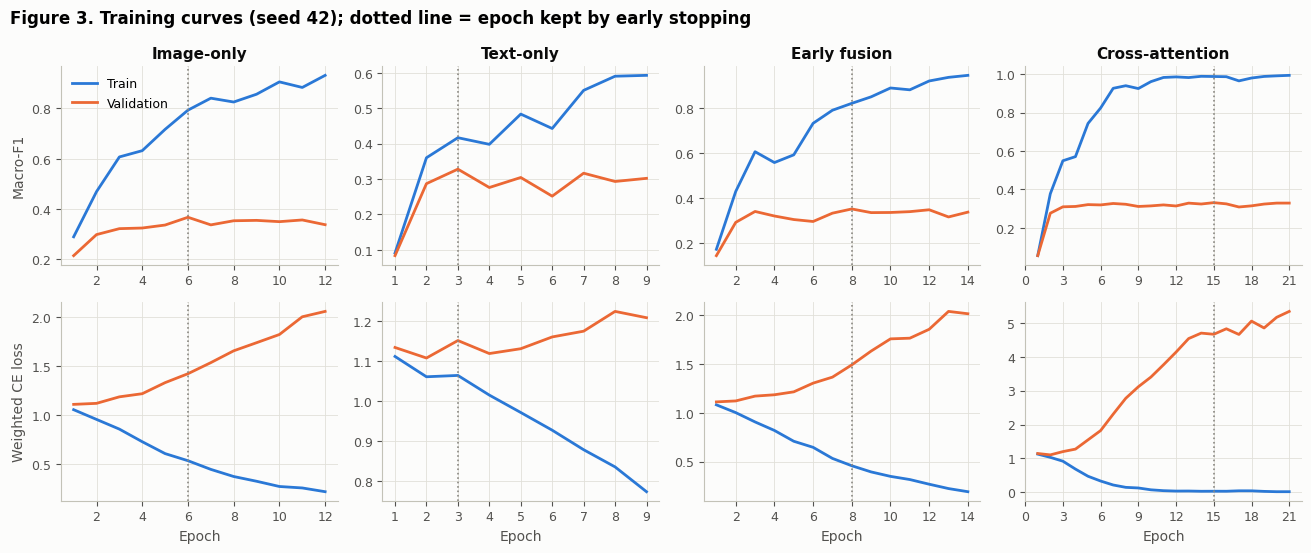

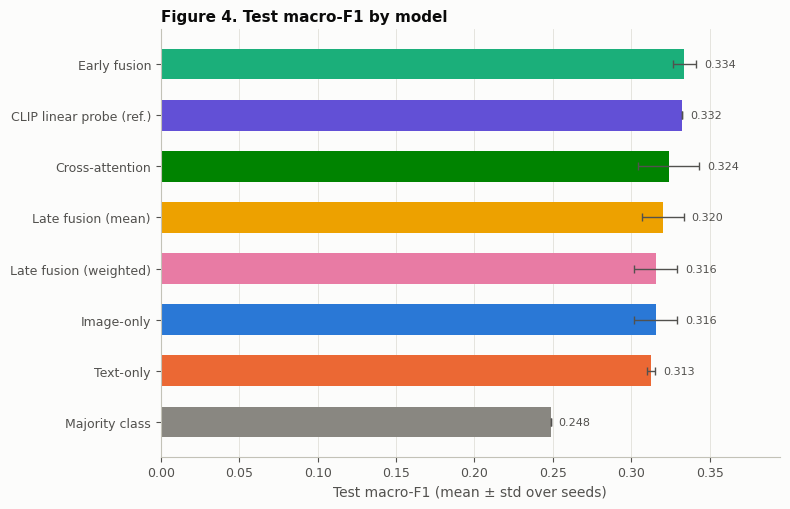

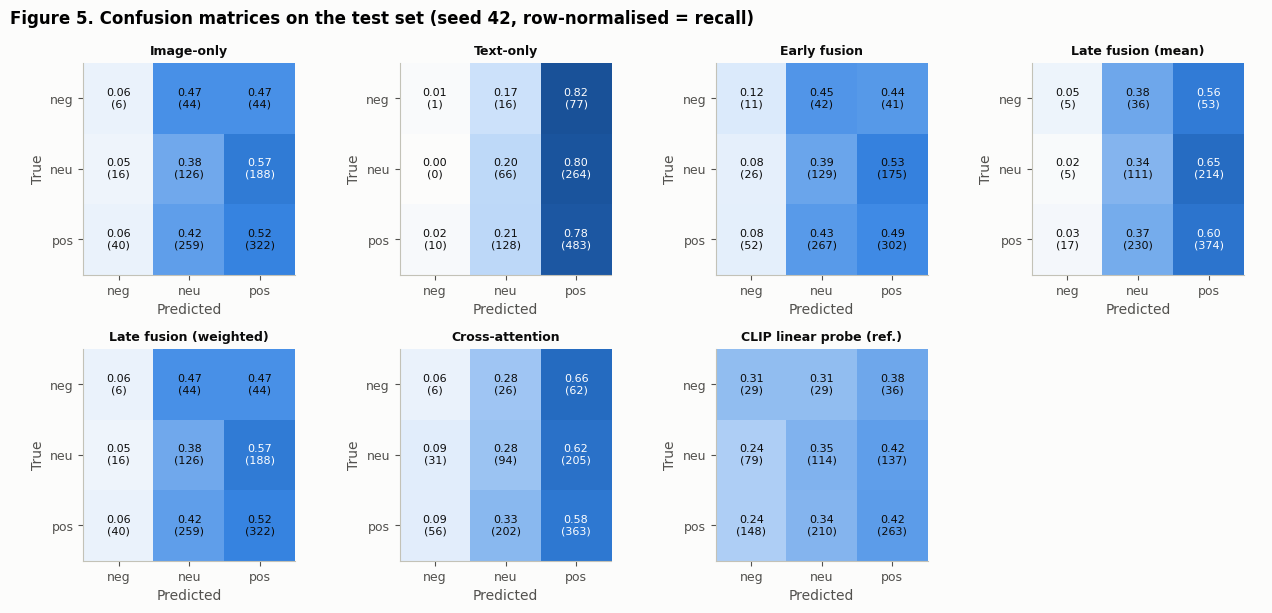

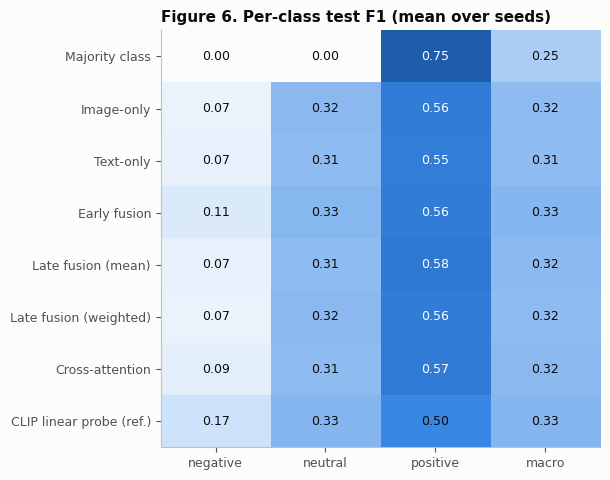

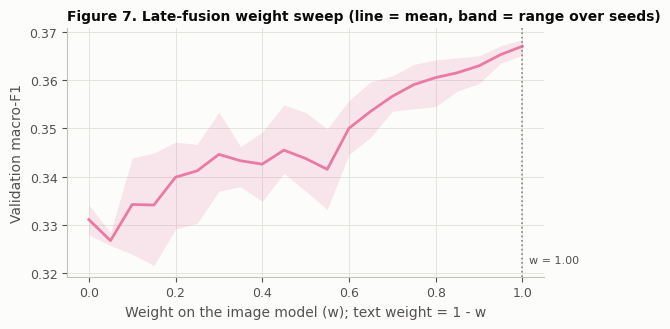

In [24]:
trained = list(BUILDERS)
fig, axes = plt.subplots(2, len(trained), figsize=(3.3 * len(trained), 5.6), sharex=False)
axes = np.atleast_2d(axes)
for j, name in enumerate(trained):
    h, be = get_run(name, seed0)["hist"], get_run(name, seed0)["best_epoch"]
    for i, (metric, label) in enumerate([("f1", "Macro-F1"), ("loss", "Weighted CE loss")]):
        ax = axes[i, j]
        ax.plot(h.epoch, h[f"train_{metric}"], color=PAL["blue"], label="Train")
        ax.plot(h.epoch, h[f"val_{metric}"], color=PAL["orange"], label="Validation")
        ax.axvline(be, color=MUTED, ls=":", lw=1.2)
        if i == 0: ax.set_title(name)
        if j == 0: ax.set_ylabel(label)
        if i == 1: ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0, 0].legend(loc="best")
fig.suptitle("Figure 3. Training curves (seed 42); dotted line = epoch kept by early stopping", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); savefig(fig, "fig03_training_curves")

mu, sd = agg[("macro_f1", "mean")], agg[("macro_f1", "std")].fillna(0)
order_bar = mu.sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(8, 0.5 * len(order_bar) + 1.2))
ax.barh(order_bar, mu[order_bar], xerr=sd[order_bar], color=[MODEL_COLORS[m] for m in order_bar], height=0.6,
        error_kw=dict(ecolor=INK2, lw=1, capsize=3))
for k, m in enumerate(order_bar):
    ax.text(mu[m] + sd[m] + 0.005, k, f"{mu[m]:.3f}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("Test macro-F1 (mean ± std over seeds)"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(mu + sd) * 1.15)
ax.set_title("Figure 4. Test macro-F1 by model", loc="left")
fig.tight_layout(); savefig(fig, "fig04_model_comparison")

show = [m for m in ORDER if m != "Majority class"]
ncol = 4; nrow = int(np.ceil(len(show) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.1 * nrow))
axes = np.array(axes).reshape(-1)
for ax, m in zip(axes, show):
    cm = confusion_matrix(y_te, P42[m].argmax(1), labels=range(len(CLASSES)))
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap=SEQ, vmin=0, vmax=1)
    for a in range(len(CLASSES)):
        for b in range(len(CLASSES)):
            ax.text(b, a, f"{cmn[a, b]:.2f}\n({cm[a, b]})", ha="center", va="center", fontsize=8,
                    color="white" if cmn[a, b] > 0.55 else INK)
    ax.set_xticks(range(3), [c[:3] for c in CLASSES]); ax.set_yticks(range(3), [c[:3] for c in CLASSES])
    ax.set_title(m, fontsize=9); ax.grid(False); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for ax in axes[len(show):]:
    ax.axis("off")
fig.suptitle("Figure 5. Confusion matrices on the test set (seed 42, row-normalised = recall)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); savefig(fig, "fig05_confusion_matrices")

pc = pd.DataFrame({c: agg[(f"f1_{c}", "mean")] for c in CLASSES}); pc["macro"] = agg[("macro_f1", "mean")]
fig, ax = plt.subplots(figsize=(6.2, 0.45 * len(pc) + 1.3))
ax.imshow(pc.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
for a in range(pc.shape[0]):
    for b in range(pc.shape[1]):
        ax.text(b, a, f"{pc.values[a, b]:.2f}", ha="center", va="center", fontsize=9, color="white" if pc.values[a, b] > 0.55 else INK)
ax.set_xticks(range(pc.shape[1]), pc.columns); ax.set_yticks(range(pc.shape[0]), pc.index); ax.grid(False)
ax.set_title("Figure 6. Per-class test F1 (mean over seeds)", loc="left")
fig.tight_layout(); savefig(fig, "fig06_per_class_f1")

sw = np.array(list(SWEEP.values()))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.fill_between(W_GRID, sw.min(0), sw.max(0), color=PAL["magenta"], alpha=0.18, lw=0)
ax.plot(W_GRID, sw.mean(0), color=PAL["magenta"])
wb = W_GRID[sw.mean(0).argmax()]
ax.axvline(wb, color=MUTED, ls=":", lw=1.2); ax.text(wb, sw.min() , f"  w = {wb:.2f}", color=INK2, fontsize=8, va="bottom")
ax.set_xlabel("Weight on the image model (w); text weight = 1 - w"); ax.set_ylabel("Validation macro-F1")
ax.set_title("Figure 7. Late-fusion weight sweep (line = mean, band = range over seeds)", loc="left", fontsize=10)
fig.tight_layout(); savefig(fig, "fig07_late_fusion_sweep")

### 10.4 Overfitting check
Train vs validation macro-F1 at the epoch kept by early stopping (mean over seeds). A large gap means the head memorised the training memes.

In [25]:
of = []
for name in trained:
    rs = [r for r in RUNS if r["model"] == name]
    tr_f = [r["hist"].loc[r["best_epoch"] - 1, "train_f1"] for r in rs]
    va_f = [r["hist"].loc[r["best_epoch"] - 1, "val_f1"] for r in rs]
    of.append(dict(model=name, best_epoch=np.mean([r["best_epoch"] for r in rs]), epochs_run=np.mean([r["epochs_run"] for r in rs]),
                   train_macro_f1=np.mean(tr_f), val_macro_f1=np.mean(va_f), gap=np.mean(tr_f) - np.mean(va_f),
                   test_macro_f1=agg.loc[name, ("macro_f1", "mean")]))
overfit = pd.DataFrame(of).set_index("model").round(3)
save_table(overfit, "table_overfitting"); display(overfit)

,best_epoch,epochs_run,train_macro_f1,val_macro_f1,gap,test_macro_f1
model,,,,,,
Image-only,8.667,14.667,0.864,0.367,0.497,0.316
Text-only,4.000,10.000,0.458,0.331,0.127,0.313
Early fusion,8.000,14.000,0.821,0.349,0.471,0.334
Cross-attention,10.000,16.000,0.932,0.339,0.593,0.324


### 10.5 Efficiency
Trainable parameters, training time and inference time on cached features, plus the one-off cost of feature extraction.

In [26]:
def time_inference(model, reps=5):
    idx = IDX["test"]; predict(model, idx)
    if DEV.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps): predict(model, idx)
    if DEV.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / reps / len(idx) * 1000 * 1000      # ms per 1000 memes

eff = []
for m in ORDER:
    rs = [r for r in RUNS if r["model"] == m]
    row = dict(model=m, trainable_params=rs[0]["params"], train_time_s=np.mean([r["train_s"] for r in rs]))
    if m in KEEP:
        row["inference_ms_per_1000"] = time_inference(KEEP[m])
    elif m.startswith("Late fusion"):
        row["inference_ms_per_1000"] = time_inference(KEEP["Image-only"]) + time_inference(KEEP["Text-only"])
    row["features_used"] = {"Image-only": "pooled image", "Text-only": "pooled text", "Cross-attention": "49 image + L text tokens",
                            "CLIP linear probe (ref.)": "CLIP embeddings", "Majority class": "none"}.get(m, "pooled image + text")
    eff.append(row)
efficiency = pd.DataFrame(eff).set_index("model").round(2)
save_table(efficiency, "table_efficiency"); display(efficiency)
mb = lambda t: t.element_size() * t.nelement() / 2**20
print({k: f"{v:.0f}s" for k, v in TIMES.items()})
print(f"Feature memory: pooled {mb(IMG_POOL) + mb(TXT_MEAN):.0f} MB | tokens {mb(IMG_TOK) + mb(TXT_TOK):.0f} MB")

,trainable_params,train_time_s,features_used,inference_ms_per_1000
model,,,,
Majority class,0,0.00,none,NaN
Image-only,529411,3.05,pooled image,3.42
Text-only,199171,2.21,pooled text,3.12
Early fusion,727555,2.93,pooled image + text,3.72
Late fusion (mean),728582,5.26,pooled image + text,6.52
Late fusion (weighted),728582,5.26,pooled image + text,6.51
Cross-attention,1399043,22.50,49 image + L text tokens,70.46
CLIP linear probe (ref.),3075,20.50,CLIP embeddings,NaN


{'image_check_s': '26s', 'image_features_s': '56s', 'text_features_s': '6s', 'clip_features_s': '90s'}
Feature memory: pooled 75 MB | tokens 1986 MB


## 11. Error and bias analysis
### 11.1 Do the modalities complement each other?
On the test set (seed 42): how often does fusion fix memes that *both* unimodal models get wrong, and how often does it break memes that one of them got right?

In [27]:
pi, pt, pf = (P42[m].argmax(1) for m in ["Image-only", "Text-only", BEST_FUSION])
ci_, ct_, cf_ = pi == y_te, pt == y_te, pf == y_te
comp = pd.DataFrame([
    ("Image and text models agree (Cohen's kappa)", f"{cohen_kappa_score(pi, pt):.3f}"),
    ("All three correct", int((ci_ & ct_ & cf_).sum())),
    (f"Both unimodal wrong, {BEST_FUSION} right", int((~ci_ & ~ct_ & cf_).sum())),
    (f"{BEST_FUSION} wrong, at least one unimodal right", int((~cf_ & (ci_ | ct_)).sum())),
    ("All three wrong", int((~ci_ & ~ct_ & ~cf_).sum())),
    ("Test memes", len(y_te)),
], columns=["case", "count"])
save_table(comp, "table_complementarity", index=False); display(comp)

pred_dist = pd.DataFrame({m: np.bincount(P42[m].argmax(1), minlength=3) / len(y_te) for m in ORDER}, index=CLASSES).T
pred_dist.loc["True distribution"] = np.bincount(y_te, minlength=3) / len(y_te)
save_table(pred_dist.round(3), "table_prediction_distribution")
print("Share of test memes predicted as each class (vs true share):"); display(pred_dist.round(3))

,case,count
0,Image and text models agree (Cohen's kappa),0.022
1,All three correct,281
2,"Both unimodal wrong, Late fusion (weighted) right",0
3,"Late fusion (weighted) wrong, at least one uni...",269
4,All three wrong,322
5,Test memes,1045


Share of test memes predicted as each class (vs true share):


,negative,neutral,positive
Majority class,0.000,0.000,1.000
Image-only,0.059,0.411,0.530
Text-only,0.011,0.201,0.789
Early fusion,0.085,0.419,0.496
Late fusion (mean),0.026,0.361,0.613
Late fusion (weighted),0.059,0.411,0.530
Cross-attention,0.089,0.308,0.603
CLIP linear probe (ref.),0.245,0.338,0.417
True distribution,0.090,0.316,0.594


### 11.2 Subgroup performance
Macro-F1 by amount of text and by text source. Small groups are noisy, so `n` is shown.

,attribute,group,n,Image-only,Text-only,Late fusion (weighted)
0,len_bucket,0-5 words,108,0.323,0.306,0.323
1,len_bucket,6-12,419,0.322,0.303,0.322
2,len_bucket,13-25,423,0.322,0.295,0.322
3,len_bucket,26+,95,0.284,0.316,0.284
4,text_source,corrected,1044,0.319,0.311,0.319
5,text_source,ocr_fallback,1,0.000,0.333,0.000
6,is_gif,JPEG/PNG/other,1045,0.319,0.311,0.319


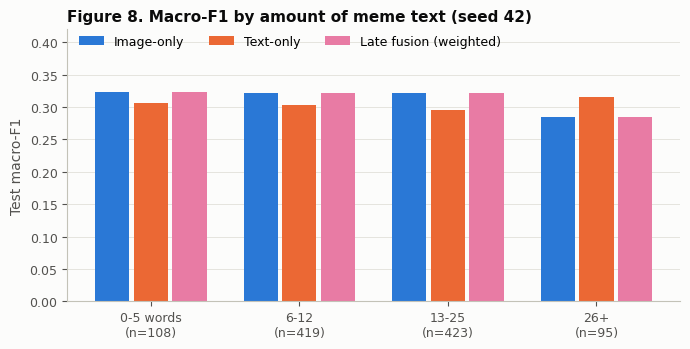

In [28]:
te = df[df["split"] == "test"].reset_index(drop=True)
te["len_bucket"] = pd.cut(te["n_words"], [-1, 5, 12, 25, 10_000], labels=["0-5 words", "6-12", "13-25", "26+"])
te["is_gif"] = np.where(te["format"].eq("GIF"), "GIF", "JPEG/PNG/other")
sub_models = ["Image-only", "Text-only", BEST_FUSION]
sub_rows = []
for col in ["len_bucket", "text_source", "is_gif"]:
    for g, part in te.groupby(col, observed=True):
        ix = part.index.to_numpy()
        row = dict(attribute=col, group=str(g), n=len(ix))
        for m in sub_models:
            row[m] = fast_macro_f1(y_te[ix], P42[m][ix].argmax(1))
        sub_rows.append(row)
subgroups = pd.DataFrame(sub_rows).round(3)
save_table(subgroups, "table_subgroups", index=False); display(subgroups)

sl = subgroups[subgroups.attribute == "len_bucket"]
x = np.arange(len(sl)); wbar = 0.26
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, m in enumerate(sub_models):
    ax.bar(x + (k - 1) * wbar, sl[m], width=wbar - 0.03, color=MODEL_COLORS[m], label=m)
ax.set_xticks(x, [f"{g}\n(n={n})" for g, n in zip(sl.group, sl.n)]); ax.grid(axis="x", visible=False)
ax.set_ylabel("Test macro-F1"); ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, 1.02))
ax.set_ylim(0, max(sl[sub_models].max()) * 1.3)
ax.set_title("Figure 8. Macro-F1 by amount of meme text (seed 42)", loc="left")
fig.tight_layout(); savefig(fig, "fig08_subgroups_text_length")

### 11.3 Failure cases
⚠️ Real memes are shown here; some may be offensive. The 8 most *confident* mistakes of the best fusion model, then memes that fusion got right while both unimodal models failed.

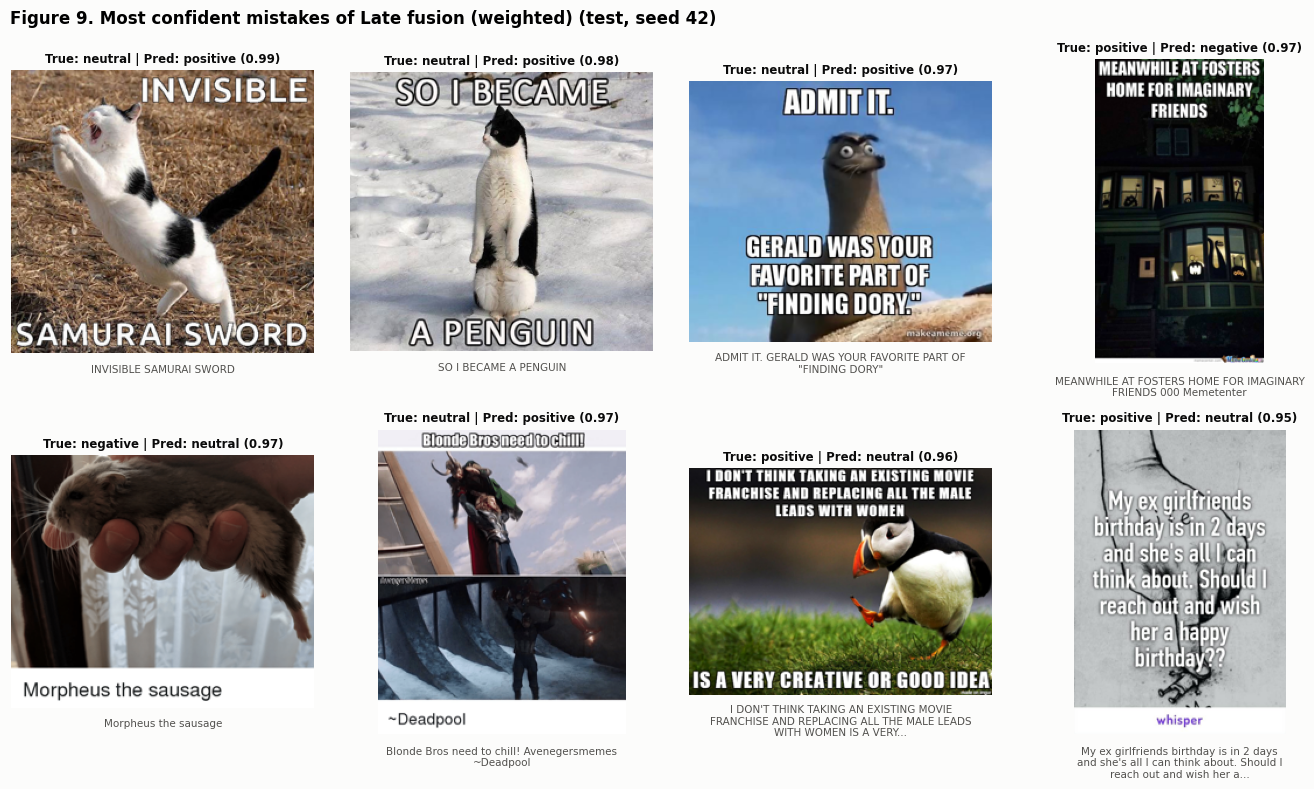

No examples for Figure 10. Memes Late fusion (weighted) got right while both unimodal models were wrong


In [29]:
def thumb(path, size=260):
    im = Image.open(path); im.seek(0); im = im.convert("RGB"); im.thumbnail((size, size)); return im

def gallery(ix_list, probs, title, name):
    if len(ix_list) == 0:
        print("No examples for", title); return
    n = len(ix_list); ncol = 4; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 4.0 * nrow))
    axes = np.array(axes).reshape(-1)
    for ax, i in zip(axes, ix_list):
        row = te.iloc[i]; p = probs[i]
        ax.imshow(thumb(row["path"])); ax.axis("off")
        ax.set_title(f"True: {CLASSES[y_te[i]]} | Pred: {CLASSES[p.argmax()]} ({p.max():.2f})", fontsize=8.5)
        snippet = textwrap.shorten(row["text"], 110, placeholder="...")
        ax.text(0.5, -0.04, textwrap.fill(snippet, 42), transform=ax.transAxes, ha="center", va="top", fontsize=7.5, color=INK2)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(); savefig(fig, name)

pb = P42[BEST_FUSION]
wrong = np.where(pb.argmax(1) != y_te)[0]
worst = wrong[np.argsort(-pb[wrong].max(1))][:8]
gallery(worst, pb, f"Figure 9. Most confident mistakes of {BEST_FUSION} (test, seed 42)", "fig09_failure_cases")
fixed = np.where(~ci_ & ~ct_ & cf_)[0][:4]
gallery(fixed, pb, f"Figure 10. Memes {BEST_FUSION} got right while both unimodal models were wrong", "fig10_fusion_fixes")

fail_table = te.iloc[worst][["image_name", "text", "text_source", "n_words"]].assign(
    true=[CLASSES[y_te[i]] for i in worst], pred=[CLASSES[pb[i].argmax()] for i in worst], confidence=pb[worst].max(1).round(3))
save_table(fail_table, "table_failure_cases", index=False)

### 11.4 Where does the text look? (cross-attention maps)
Average text-to-image attention over the 7×7 ResNet grid, overlaid on the meme as the model saw it (224×224). Brighter = more attention.

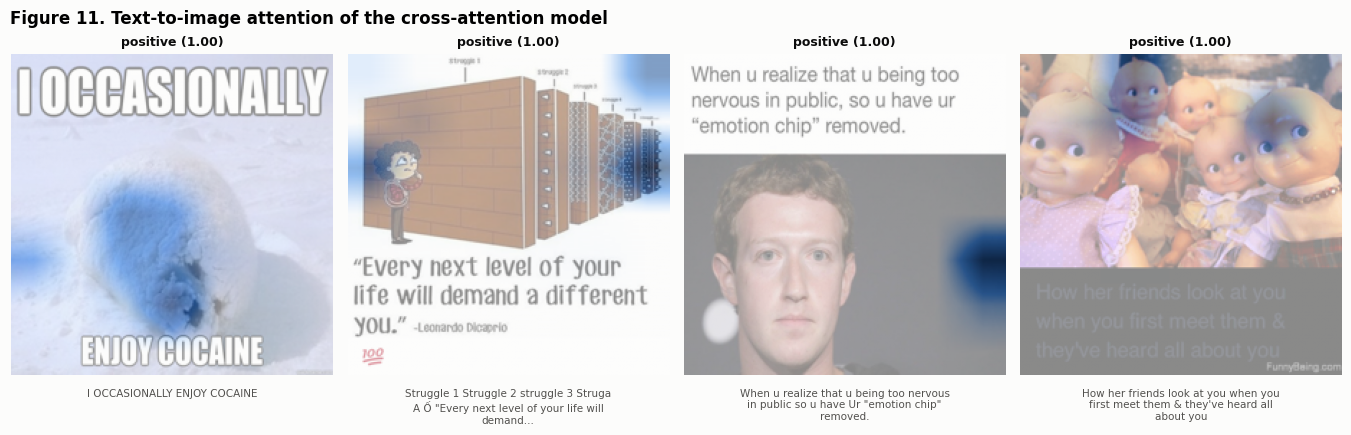

In [30]:
if "Cross-attention" in KEEP:
    xm = KEEP["Cross-attention"]; xm.eval()
    pxa = P42["Cross-attention"]
    good = np.where((pxa.argmax(1) == y_te) & (te["text_source"].to_numpy() != "none"))[0]
    pick = good[np.argsort(-pxa[good].max(1))][:4] if len(good) else []
    if len(pick):
        with torch.no_grad():
            _, att = xm(batch(IDX["test"][torch.tensor(pick, device=DEV)]), return_attn=True)
        att = att.cpu().numpy().reshape(-1, 7, 7)
        fig, axes = plt.subplots(1, len(pick), figsize=(3.4 * len(pick), 4.0))
        axes = np.atleast_1d(axes)
        for ax, i, a in zip(axes, pick, att):
            im = Image.open(te.iloc[i]["path"]); im.seek(0); im = im.convert("RGB").resize((224, 224))
            heat = np.array(Image.fromarray((a / a.max() * 255).astype(np.uint8)).resize((224, 224), Image.BILINEAR)) / 255
            ax.imshow(im); ax.imshow(heat, cmap=SEQ, alpha=0.55, vmin=0, vmax=1); ax.axis("off")
            ax.set_title(f"{CLASSES[y_te[i]]} ({pxa[i].max():.2f})", fontsize=9)
            ax.text(0.5, -0.04, textwrap.fill(textwrap.shorten(te.iloc[i]["text"], 90, placeholder="..."), 40),
                    transform=ax.transAxes, ha="center", va="top", fontsize=7.5, color=INK2)
        fig.suptitle("Figure 11. Text-to-image attention of the cross-attention model", x=0.01, ha="left", fontsize=12, fontweight="bold")
        fig.tight_layout(); savefig(fig, "fig11_attention_maps")

## 12. Save everything
Writes `results/config.json` and `results/key_numbers.json`, prints the numbers needed for the report, and zips `results/` for download.

In [31]:
key = dict(
    n_memes_raw=int(n_total), n_memes_used=int(len(df)), split_sizes={s: int((df.split == s).sum()) for s in ["train", "val", "test"]},
    best_fusion_by_val=BEST_FUSION, best_unimodal_by_val=BEST_UNI, max_len=CFG["max_len"], truncation_rate=round(trunc_rate, 4),
    test_macro_f1_mean={m: round(float(agg.loc[m, ("macro_f1", "mean")]), 4) for m in ORDER},
    test_macro_f1_std={m: (None if np.isnan(agg.loc[m, ("macro_f1", "std")]) else round(float(agg.loc[m, ("macro_f1", "std")]), 4)) for m in ORDER},
    times_s={k: round(v, 1) for k, v in TIMES.items()},
    late_fusion_w_image={r["seed"]: r["w_image"] for r in RUNS if r["model"] == "Late fusion (weighted)"},
)
json.dump(CFG, open(OUT / "config.json", "w"), indent=2, default=str)
json.dump(key, open(OUT / "key_numbers.json", "w"), indent=2, default=str)
print(json.dumps(key, indent=2, default=str))

with zipfile.ZipFile("results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        z.write(p)
print("Saved results.zip with", sum(1 for _ in OUT.rglob('*.*')), "files")
try:
    from google.colab import files
    files.download("results.zip")
except Exception:
    pass

{
  "n_memes_raw": 6992,
  "n_memes_used": 6966,
  "split_sizes": {
    "train": 4876,
    "val": 1045,
    "test": 1045
  },
  "best_fusion_by_val": "Late fusion (weighted)",
  "best_unimodal_by_val": "Image-only",
  "max_len": 64,
  "truncation_rate": 0.0093,
  "test_macro_f1_mean": {
    "Majority class": 0.2485,
    "Image-only": 0.3156,
    "Text-only": 0.3127,
    "Early fusion": 0.3338,
    "Late fusion (mean)": 0.3199,
    "Late fusion (weighted)": 0.3156,
    "Cross-attention": 0.3239,
    "CLIP linear probe (ref.)": 0.3324
  },
  "test_macro_f1_std": {
    "Majority class": null,
    "Image-only": 0.0136,
    "Text-only": 0.0025,
    "Early fusion": 0.0075,
    "Late fusion (mean)": 0.0134,
    "Late fusion (weighted)": 0.0136,
    "Cross-attention": 0.0194,
    "CLIP linear probe (ref.)": null
  },
  "times_s": {
    "image_check_s": 26.2,
    "image_features_s": 55.7,
    "text_features_s": 6.5,
    "clip_features_s": 90.0
  },
  "late_fusion_w_image": {
    "42": 1.0,
    

Saved results.zip with 25 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>